# Experimento final v3 — reserva por demanda (máximo por enlace) nos 10 cenários base

Setup mínimo do artigo:

| variante | escopo | conjuntos $K$ | rodadas por base |
|---|---|---|---|
| sem reserva (First-Fit disaster-aware) | — | independe de $K$ | 1 |
| First-Fit | — | independe de $K$ | 1 |
| reserva por demanda, máximo por enlace | cooperativa | os 32 | 32 |
| reserva por demanda | individual | independe de $K$ | 1 |
| reserva fixa 25 / 55 / 85% | cooperativa | só $K=\mathcal{I}$ | 3 |

Variantes que independem de $K$ rodam uma vez e são replicadas para todos os $K$. A reserva fixa só entra na curva de compromisso $\eta \times B_n$ com todos cooperando.

Num enlace protegido usado por vários membros, a reserva é a **maior** necessidade entre eles (não a soma). A proteção individual não muda (cada enlace tem um único dono), então reaproveita as rodadas do v2. Resultados em `output/cooperation_experiment_v3_dist*`; figuras e CSVs em `final_v3/`.

In [1]:
import json
import os
import pickle
from concurrent.futures import ProcessPoolExecutor, as_completed
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from experiment_worker import calcular_prefixo, metrics_path, prefixo_path, run_cooperation_experiment
from run_cooperation_experiment import (
    COOP_PATH,
    PROTECOES,
    montar_tarefas,
    nome_reserva,
    nome_reserva_principal,
    pasta_saida,
    resultado_completo,
)
from simulador.analysis.cooperation_metrics import expandir_para_todos_k

%matplotlib inline

## Parâmetros

In [2]:
BASE_INDICES = list(range(10))
FIXAS = [25, 55, 85]          # reserva fixa (cooperativa), só com K = I
DESTINO = "distancia"         # destino da migração: nó mais distante em km
RECORTAR = True               # termina cada rodada em t_d (métricas só usam requisições anteriores)
USAR_PREFIXO = True           # simula [0, tau_min) uma vez por base e retoma dali
MAX_WORKERS = min(os.cpu_count() or 4, 8)

REFERENCIA = pasta_saida(None, None, sem_pesos=True, destino=DESTINO)
PASTA_DEMANDA = pasta_saida(None, "demanda_max", True, DESTINO)
PASTA_DEMANDA_IND = pasta_saida(None, "demanda_isolado", True, DESTINO)
PASTAS_FIXA = {p: pasta_saida(None, nome_reserva_principal(p), True, DESTINO) for p in FIXAS}  # main path only
FIGURAS = REFERENCIA / "final_v3"
FIGURAS.mkdir(parents=True, exist_ok=True)

def isp_ids_da_base(b):
    with open(COOP_PATH.format(i=b), "rb") as f:
        return sorted(isp.isp_id for isp in pickle.load(f).lista_de_isps)

IDS = {b: isp_ids_da_base(b) for b in BASE_INDICES}
I = len(IDS[BASE_INDICES[0]])
print({b: ids for b, ids in IDS.items()})

{0: [0, 1, 2, 3, 4], 1: [0, 1, 2, 3, 4], 2: [0, 1, 2, 3, 4], 3: [0, 1, 2, 3, 4], 4: [0, 1, 2, 3, 4], 5: [0, 1, 2, 3, 4], 6: [0, 1, 2, 3, 4], 7: [0, 1, 2, 3, 4], 8: [0, 1, 2, 3, 4], 9: [0, 1, 2, 3, 4]}


## Rodadas pendentes

In [3]:
def completar(tarefas, pasta, protecao, rotulo):
    pasta.mkdir(parents=True, exist_ok=True)
    for t in tarefas:
        t.update(output_dir=str(pasta), protecao=protecao, sem_pesos=True,
                 destino_migracao=DESTINO, recortar_janela=RECORTAR, rotulo=rotulo)
    return tarefas

tarefas = []
tarefas += completar(montar_tarefas(BASE_INDICES, REFERENCIA, first_fit=True, somente_k_vazio=True),
                     REFERENCIA, None, "sem reserva / First-Fit")
tarefas += completar(montar_tarefas(BASE_INDICES, PASTA_DEMANDA, first_fit=False),
                     PASTA_DEMANDA, PROTECOES["demanda_max"], "demanda cooperativa")
tarefas += completar(montar_tarefas(BASE_INDICES, PASTA_DEMANDA_IND, first_fit=False, somente_k_vazio=True),
                     PASTA_DEMANDA_IND, PROTECOES["demanda_isolado"], "demanda individual")

def tarefa_k_todos(b, pasta, protecao, rotulo):
    return {"base_path": COOP_PATH.format(i=b), "base_index": b, "cooperantes": tuple(IDS[b]),
            "variante": "cooperacao", "output_dir": str(pasta), "protecao": protecao, "sem_pesos": True,
            "destino_migracao": DESTINO, "recortar_janela": RECORTAR, "rotulo": rotulo}

for p, pasta in PASTAS_FIXA.items():
    pasta.mkdir(parents=True, exist_ok=True)
    for b in BASE_INDICES:
        if not resultado_completo(metrics_path(pasta, IDS[b], b)):
            tarefas.append(tarefa_k_todos(b, pasta, PROTECOES[nome_reserva_principal(p)], f"fixa {p}% K=I"))

# Verificação: a demanda individual não pode depender de K (uma rodada extra, base 0)
b0 = BASE_INDICES[0]
if not resultado_completo(metrics_path(PASTA_DEMANDA_IND, IDS[b0], b0)):
    tarefas.append(tarefa_k_todos(b0, PASTA_DEMANDA_IND, PROTECOES["demanda_isolado"], "verificação"))

print(f"{len(tarefas)} rodadas pendentes | {len(BASE_INDICES)} bases | {MAX_WORKERS} processos")
pd.Series([t["rotulo"] for t in tarefas]).value_counts()

29 rodadas pendentes | 10 bases | 8 processos


demanda cooperativa    29
Name: count, dtype: int64

## Prefixos compartilhados (um por base, em paralelo)

In [4]:
PREFIXOS = {}
if USAR_PREFIXO:
    faltando = [b for b in BASE_INDICES if not prefixo_path("output", b).exists()]
    if faltando:
        print(f"calculando prefixos das bases {faltando}...")
        with ProcessPoolExecutor(max_workers=MAX_WORKERS) as ex:
            list(ex.map(calcular_prefixo, [COOP_PATH.format(i=b) for b in faltando],
                        [prefixo_path("output", b) for b in faltando]))
    PREFIXOS = {b: str(prefixo_path("output", b)) for b in BASE_INDICES}
for t in tarefas:
    if t["base_index"] in PREFIXOS:
        t["prefixo"] = PREFIXOS[t["base_index"]]
for idx, t in enumerate(tarefas):
    t.update(run_index=idx, total_runs=len(tarefas))

## Executar

In [5]:
inicio = datetime.now()
falhas = []
if tarefas:
    with ProcessPoolExecutor(max_workers=MAX_WORKERS) as executor:
        futures = {executor.submit(run_cooperation_experiment, t): t for t in tarefas}
        for n, future in enumerate(as_completed(futures), start=1):
            r = future.result()
            estado = "✓" if r["success"] else "✗"
            print(f"[{n}/{len(tarefas)}] {estado} {futures[future]['rotulo']} base={r['base_index']} {r['K']}  ({datetime.now() - inicio})")
            if not r["success"]:
                falhas.append(r)
print(f"Duração: {datetime.now() - inicio} | falhas: {len(falhas)}")

[1/29] ✓ demanda cooperativa base=6 K_0-2-3-4  (0:01:07.576385)


[2/29] ✓ demanda cooperativa base=6 K_0-1-2-3  (0:01:08.406974)
[3/29] ✓ demanda cooperativa base=6 K_0-1-2-4  (0:01:08.518951)


[4/29] ✓ demanda cooperativa base=6 K_1-2-4  (0:01:08.728916)
[5/29] ✓ demanda cooperativa base=6 K_0-3-4  (0:01:08.773622)
[6/29] ✓ demanda cooperativa base=6 K_0-1-3-4  (0:01:08.920499)


[7/29] ✓ demanda cooperativa base=6 K_1-2-3-4  (0:01:08.949971)


[8/29] ✓ demanda cooperativa base=6 K_2-3-4  (0:01:09.215998)


[9/29] ✓ demanda cooperativa base=6 K_0-1-2-3-4  (0:02:19.589897)


... (15 outputs left out)

[27/29] ✓ demanda cooperativa base=9 K_0-1-2-4  (0:04:59.956170)


[28/29] ✓ demanda cooperativa base=9 K_0-1-3-4  (0:05:00.724026)


[29/29] ✓ demanda cooperativa base=9 K_0-1-2-3-4  (0:05:01.525701)
[3/29] ✓ base=6 K_2-3-4: eta(K)=0.635 Gamma=-0.120
[16/29] ✓ base=7 K_1-2-3: eta(K)=0.844 Gamma=0.044
[24/29] ✓ base=8 K_0-1-3-4: eta(K)=0.496 Gamma=-0.389
[26/29] ✓ base=9 K_0-1-4: eta(K)=0.641 Gamma=-0.294
[4/29] ✓ base=6 K_0-1-2-3: eta(K)=0.722 Gamma=0.200
[10/29] ✓ base=7 K_0-3: eta(K)=0.828 Gamma=0.067
[18/29] ✓ base=7 K_0-1-2-3: eta(K)=0.790 Gamma=-0.210
[27/29] ✓ base=9 K_0-1-2-4: eta(K)=0.745 Gamma=-0.255
[5/29] ✓ base=6 K_0-1-2-4: eta(K)=0.732 Gamma=0.231
[11/29] ✓ base=7 K_1-2: eta(K)=0.766 Gamma=-0.100
[19/29] ✓ base=7 K_0-1-2-4: eta(K)=0.785 Gamma=-0.215
[28/29] ✓ base=9 K_0-1-3-4: eta(K)=0.731 Gamma=-0.139
[8/29] ✓ base=6 K_1-2-3-4: eta(K)=0.729 Gamma=0.191
[15/29] ✓ base=7 K_0-3-4: eta(K)=0.878 Gamma=0.230
[22/29] ✓ base=7 K_1-2-3-4: eta(K)=0.897 Gamma=0.275
[2/29] ✓ base=6 K_1-2-4: eta(K)=0.803 Gamma=0.293
[12/29] ✓ base=7 K_0-1-2: eta(K)=0.711 Gamma=-0.289
[20/29] ✓ base=7 K_0-1-3-4: eta(K)=0.807 Gamma=0

Duração: 0:05:02.089444 | falhas: 0


## Verificação: demanda individual igual para $K=\emptyset$ e $K=\mathcal{I}$

In [6]:
a = json.loads(metrics_path(PASTA_DEMANDA_IND, (), b0).read_text())["summary"]
z = json.loads(metrics_path(PASTA_DEMANDA_IND, IDS[b0], b0).read_text())["summary"]
campos = ["eta_todos", "B_n", "B_m", "U"]
print({c: (a[c], z[c]) for c in campos})
assert all(abs(a[c] - z[c]) < 1e-12 for c in campos), "a demanda individual mudou com K!"
print("✓ idêntico")

{'eta_todos': (0.7125481600285128, 0.7125481600285128), 'B_n': (0.35431023273956574, 0.35431023273956574), 'B_m': (0.6172056921086675, 0.6172056921086675), 'U': (0.4285739193759964, 0.4285739193759964)}
✓ idêntico


## Carregar resultados

In [7]:
resumos, linhas_isp = [], []

def ler(pasta, padrao):
    return [json.loads(f.read_text()) for f in sorted(pasta.glob(padrao))]

def adicionar(resultados, mecanismo, expandir):
    for r in resultados:
        b = r["base_index"]
        if b not in IDS:
            continue
        if expandir:
            if r["K"] not in ("K_none", "first_fit"):
                continue
            s, p = expandir_para_todos_k(r, IDS[b])
        else:
            s, p = [r["summary"]], r["per_isp"]
        resumos.extend({**x, "mecanismo": mecanismo} for x in s)
        linhas_isp.extend({**x, "mecanismo": mecanismo} for x in p)

adicionar(ler(REFERENCIA, "K_none/metrics_*.json"), "sem reserva", True)
adicionar(ler(REFERENCIA, "first_fit/metrics_*.json"), "First-Fit", True)
adicionar(ler(PASTA_DEMANDA, "K_*/metrics_*.json"), "demanda cooperativa", False)
adicionar(ler(PASTA_DEMANDA_IND, "K_none/metrics_*.json"), "demanda individual", True)
for p, pasta in PASTAS_FIXA.items():
    for b in BASE_INDICES:
        caminho = metrics_path(pasta, IDS[b], b)
        if caminho.exists():
            adicionar([json.loads(caminho.read_text())], f"fixa {p}%", False)

resumo = pd.DataFrame(resumos).drop(columns=["U_links", "prot_historico_ganho"], errors="ignore")
por_isp = pd.DataFrame(linhas_isp)

# Bloqueio de migração por grupo, ponderado pelo número de requisições de migração
def _bm(g):
    n = g["n_migracao_i"].sum()
    return (g["B_m_i"] * g["n_migracao_i"]).sum() / n if n else np.nan

chaves = ["mecanismo", "base_index", "K"]
bm = (por_isp.groupby(chaves + ["em_K"]).apply(_bm).unstack("em_K")
      .rename(columns={True: "B_m_K", False: "B_m_isolados"}).reset_index())
resumo = resumo.merge(bm, on=chaves, how="left")

ref = resumo[resumo["mecanismo"] == "sem reserva"].set_index(["base_index", "K"])
for col in ["eta_todos", "B_n", "B_m", "B", "U", "eta_K", "eta_isolados", "B_n_K", "B_n_isolados"]:
    resumo["d_" + col] = resumo[col].values - ref.loc[list(zip(resumo["base_index"], resumo["K"])), col].values

resumo.to_csv(FIGURAS / "resumo_v3.csv", index=False)
por_isp.to_csv(FIGURAS / "resumo_v3_por_isp.csv", index=False)
ORDEM = ["sem reserva", "First-Fit", "demanda individual", "demanda cooperativa"] + [f"fixa {p}%" for p in FIXAS]
print(resumo.groupby("mecanismo")["base_index"].nunique().reindex(ORDEM), "\n")
resumo.groupby("mecanismo").size().reindex(ORDEM)

mecanismo
sem reserva            10
First-Fit              10
demanda individual     10
demanda cooperativa    10
fixa 25%               10
fixa 55%               10
fixa 85%               10
Name: base_index, dtype: int64 



/var/folders/z5/7m2dt1d518d7g_0gxw25z2wr0000gn/T/ipykernel_98465/79715781.py:39: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  bm = (por_isp.groupby(chaves + ["em_K"]).apply(_bm).unstack("em_K")


mecanismo
sem reserva            320
First-Fit              320
demanda individual     320
demanda cooperativa    320
fixa 25%                10
fixa 55%                10
fixa 85%                10
dtype: int64

## Tabela principal

Média e desvio padrão **entre as bases** (cada base é primeiro resumida: média sobre os 32 $K$, ou o valor com $K=\mathcal{I}$). Eficiência $=\Delta\eta/\Delta B_n$ em relação à referência.

In [8]:
def por_base(df, col):
    return df.groupby(["mecanismo", "base_index"])[col].mean()

def media_dp(s):
    g = s.groupby(level="mecanismo")
    return g.mean().map("{:.3f}".format) + " ± " + g.std().map("{:.3f}".format)

todos_k = resumo[resumo["mecanismo"].isin(ORDEM[:4])]
k_todos = resumo[resumo["k"] == I]
tabela = pd.DataFrame({
    "η (média K)": media_dp(por_base(todos_k, "eta_todos")),
    "B_n (média K)": media_dp(por_base(todos_k, "B_n")),
    "η (K=I)": media_dp(por_base(k_todos, "eta_todos")),
    "B_n (K=I)": media_dp(por_base(k_todos, "B_n")),
    "B_m (K=I)": media_dp(por_base(k_todos, "B_m")),
    "B (K=I)": media_dp(por_base(k_todos, "B")),
    "U (K=I)": media_dp(por_base(k_todos, "U")),
})
ef = (por_base(k_todos, "d_eta_todos") / por_base(k_todos, "d_B_n")).replace([np.inf, -np.inf], np.nan)
tabela["Δη/ΔB_n (K=I)"] = media_dp(ef)
tabela.reindex(ORDEM)

,η (média K),B_n (média K),η (K=I),B_n (K=I),B_m (K=I),B (K=I),U (K=I),Δη/ΔB_n (K=I)
mecanismo,,,,,,,,
sem reserva,0.672 ± 0.081,0.368 ± 0.029,0.672 ± 0.081,0.368 ± 0.029,0.638 ± 0.047,0.463 ± 0.030,0.442 ± 0.021,nan ± nan
First-Fit,0.556 ± 0.095,0.336 ± 0.024,0.556 ± 0.095,0.336 ± 0.024,0.702 ± 0.040,0.464 ± 0.027,0.415 ± 0.015,3.563 ± 0.682
demanda individual,0.685 ± 0.087,0.373 ± 0.028,0.685 ± 0.087,0.373 ± 0.028,0.633 ± 0.051,0.464 ± 0.029,0.442 ± 0.020,3.450 ± 4.773
demanda cooperativa,0.688 ± 0.085,0.374 ± 0.028,0.760 ± 0.101,0.401 ± 0.038,0.604 ± 0.059,0.473 ± 0.028,0.448 ± 0.019,2.958 ± 0.598
fixa 25%,NaN,NaN,0.728 ± 0.088,0.412 ± 0.028,0.613 ± 0.053,0.482 ± 0.030,0.423 ± 0.021,1.274 ± 0.272
fixa 55%,NaN,NaN,0.796 ± 0.099,0.483 ± 0.027,0.579 ± 0.059,0.517 ± 0.029,0.401 ± 0.023,1.056 ± 0.277
fixa 85%,NaN,NaN,0.860 ± 0.102,0.610 ± 0.034,0.536 ± 0.068,0.585 ± 0.027,0.380 ± 0.026,0.768 ± 0.164


## Cruzamento: a partir de que $|K|$ a cooperação supera a proteção individual?

Por base: menor $|K|$ em que o $\eta$ médio da demanda cooperativa passa o da demanda individual.

In [9]:
eta_k = resumo.groupby(["mecanismo", "base_index", "k"])["eta_todos"].mean()
coop, ind = eta_k.loc["demanda cooperativa"], eta_k.loc["demanda individual"]
cruzamento = {}
for b in BASE_INDICES:
    acima = [k for k in range(1, I + 1) if coop.loc[(b, k)] > ind.loc[(b, k)]]
    cruzamento[b] = min(acima) if acima else None
cruz = pd.Series(cruzamento, name="|K| de cruzamento")
print(cruz.to_string())
print("\ndistribuição:", cruz.value_counts(dropna=False).sort_index().to_dict())

0    3
1    3
2    1
3    1
4    4
5    1
6    2
7    2
8    4
9    5

distribuição: {1: 3, 2: 2, 3: 2, 4: 2, 5: 1}


## Figuras

In [10]:
CORES = {"sem reserva": "#52514e", "First-Fit": "#a3a29e", "demanda individual": "#eb6834",
         "demanda cooperativa": "#2a78d6", "fixa": "#1baf7a"}
TEXTO, GRADE = "#52514e", "#e5e4df"

def estilo(ax, titulo, ylabel, xlabel="|K| (provedores cooperando)"):
    ax.set_title(titulo, loc="left", fontsize=12, color="#0b0b0b")
    ax.set_xlabel(xlabel, color=TEXTO); ax.set_ylabel(ylabel, color=TEXTO)
    ax.tick_params(colors=TEXTO); ax.grid(axis="y", color=GRADE, linewidth=0.8)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)

def curva(ax, mec, col, **kw):
    s = resumo[resumo["mecanismo"] == mec].groupby(["base_index", "k"])[col].mean().unstack("base_index")
    m, d = s.mean(axis=1), s.std(axis=1)
    tracejada = mec in ("sem reserva", "First-Fit", "demanda individual")
    ax.plot(m.index, m.values, "--" if tracejada else "-", color=CORES[mec], linewidth=2,
            marker=None if tracejada else "o", markersize=7, label=mec, **kw)
    ax.fill_between(m.index, m - d, m + d, color=CORES[mec], alpha=0.12, linewidth=0)

### Figura 1 — valor da cooperação e cruzamento

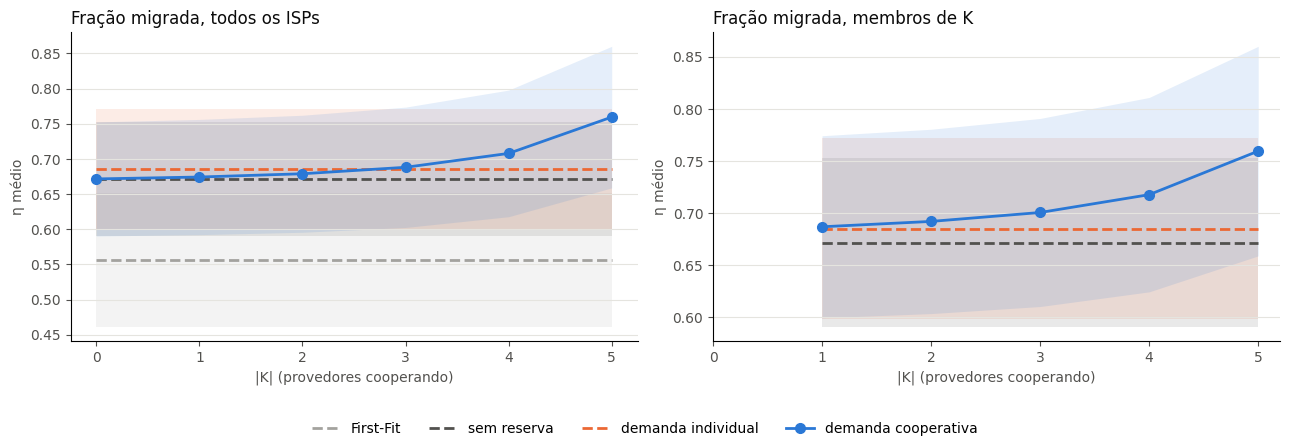

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for mec in ["First-Fit", "sem reserva", "demanda individual", "demanda cooperativa"]:
    curva(axes[0], mec, "eta_todos")
    if mec != "First-Fit":
        curva(axes[1], mec, "eta_K")
estilo(axes[0], "Fração migrada, todos os ISPs", "η médio")
estilo(axes[1], "Fração migrada, membros de K", "η médio")
for ax in axes:
    ax.set_xticks(range(I + 1))
h, l = axes[0].get_legend_handles_labels()
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.legend(h, l, frameon=False, loc="lower center", ncol=4)
fig.savefig(FIGURAS / "fig1_cooperacao.png", dpi=150, bbox_inches="tight")
plt.show()

### Figura 2 — compromisso $\eta \times B_n$ com todos cooperando

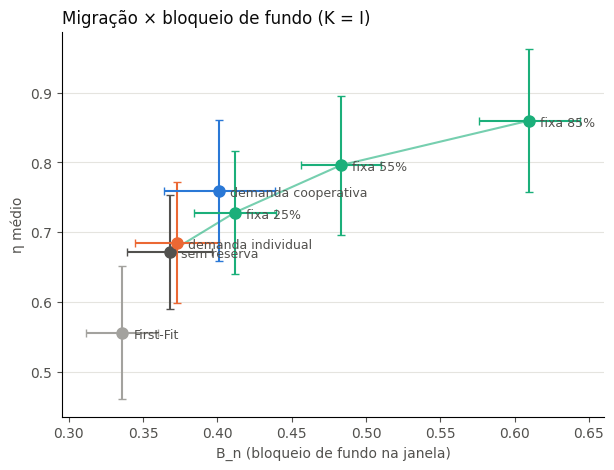

In [12]:
pts = k_todos.groupby(["mecanismo", "base_index"])[["eta_todos", "B_n"]].mean().groupby(level="mecanismo")
m, d = pts.mean(), pts.std()
fig, ax = plt.subplots(figsize=(7, 5))
fixas = [f"fixa {p}%" for p in FIXAS]
ref_pt = m.loc["sem reserva"]
xs = [ref_pt["B_n"]] + [m.loc[f, "B_n"] for f in fixas]
ys = [ref_pt["eta_todos"]] + [m.loc[f, "eta_todos"] for f in fixas]
ax.plot(xs, ys, color=CORES["fixa"], linewidth=1.5, alpha=0.6)
for mec in ["sem reserva", "First-Fit", "demanda individual", "demanda cooperativa"] + fixas:
    cor = CORES.get(mec, CORES["fixa"])
    ax.errorbar(m.loc[mec, "B_n"], m.loc[mec, "eta_todos"], xerr=d.loc[mec, "B_n"], yerr=d.loc[mec, "eta_todos"],
                fmt="o", color=cor, markersize=8, capsize=3)
    ax.annotate(mec, (m.loc[mec, "B_n"], m.loc[mec, "eta_todos"]), textcoords="offset points",
                xytext=(8, -4), fontsize=9, color=TEXTO)
estilo(ax, "Migração × bloqueio de fundo (K = I)", "η médio", "B_n (bloqueio de fundo na janela)")
fig.savefig(FIGURAS / "fig2_compromisso.png", dpi=150, bbox_inches="tight")
plt.show()

### Figura 3 — custo para membros e para quem está fora de $K$

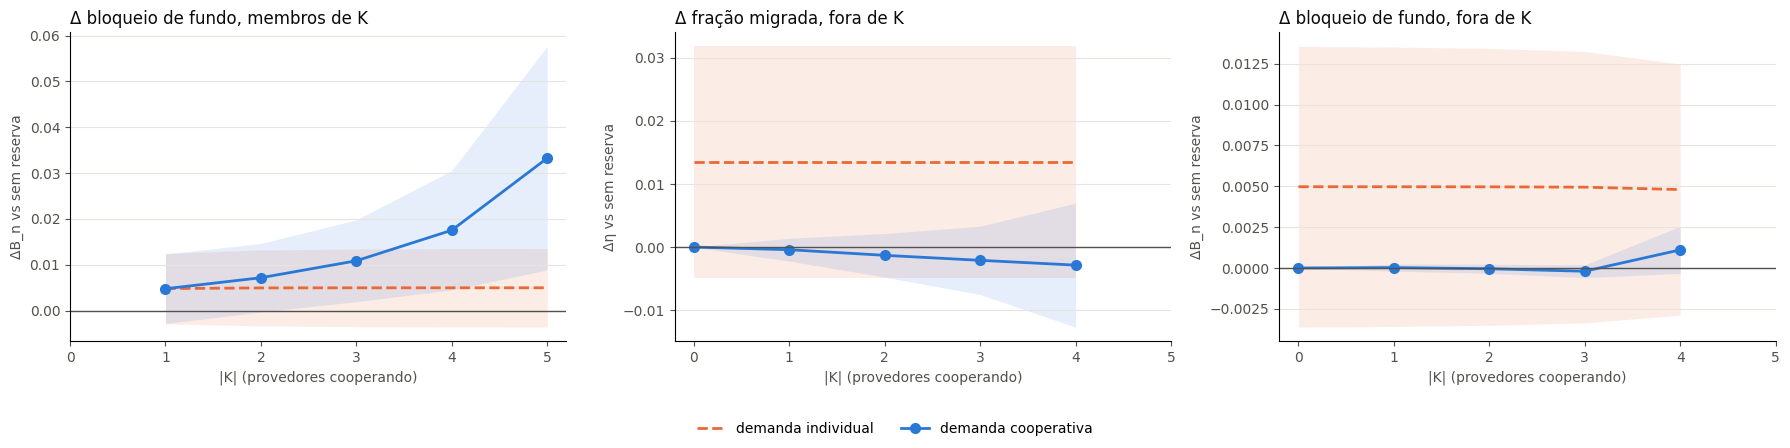

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for mec in ["demanda individual", "demanda cooperativa"]:
    curva(axes[0], mec, "d_B_n_K")
    curva(axes[1], mec, "d_eta_isolados")
    curva(axes[2], mec, "d_B_n_isolados")
estilo(axes[0], "Δ bloqueio de fundo, membros de K", "ΔB_n vs sem reserva")
estilo(axes[1], "Δ fração migrada, fora de K", "Δη vs sem reserva")
estilo(axes[2], "Δ bloqueio de fundo, fora de K", "ΔB_n vs sem reserva")
for ax in axes:
    ax.axhline(0, color=TEXTO, linewidth=1)
    ax.set_xticks(range(I + 1))
h, l = axes[0].get_legend_handles_labels()
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.legend(h, l, frameon=False, loc="lower center", ncol=2)
fig.savefig(FIGURAS / "fig3_custos.png", dpi=150, bbox_inches="tight")
plt.show()

## Por base (K = I)

In [14]:
k_todos.pivot_table(index="base_index", columns="mecanismo", values="eta_todos").reindex(columns=ORDEM).round(3)

mecanismo,sem reserva,First-Fit,demanda individual,demanda cooperativa,fixa 25%,fixa 55%,fixa 85%
base_index,,,,,,,
0,0.690,0.565,0.713,0.824,0.787,0.917,1.000
1,0.771,0.737,0.776,0.840,0.841,0.926,0.959
2,0.600,0.470,0.600,0.701,0.654,0.724,0.794
3,0.591,0.484,0.590,0.618,0.629,0.688,0.764
4,0.694,0.597,0.751,0.888,0.768,0.854,0.938
5,0.626,0.492,0.626,0.705,0.671,0.697,0.718
6,0.666,0.527,0.671,0.766,0.708,0.759,0.833
7,0.785,0.659,0.789,0.861,0.821,0.855,0.922
8,0.545,0.426,0.561,0.598,0.596,0.667,0.737
